# Machine Learning Theory: Statistical Learning Theory

> **Who is this for:** you can train models with scikit-learn and have met over- and under-fitting in [`06_model_evaluation`](../06_model_evaluation/01_model_evaluation.ipynb). Now you want to know **why** learning from a finite sample works at all, how much data is "enough", and what theory says about modern over-parameterised models. This is core material for an MS/MPhil "Advanced Machine Learning" course and comes up in research interviews.
>
> **What you will learn:**
> - The formal learning set-up: distribution $\mathcal D$, hypothesis class $\mathcal H$, loss, **true risk vs empirical risk**, and **empirical risk minimisation (ERM)**
> - The **bias–variance decomposition**, derived and then measured by simulation over hundreds of resampled training sets
> - **PAC learning** and the finite-class bound $m \ge \frac1\varepsilon(\ln|\mathcal H| + \ln\frac1\delta)$, checked empirically
> - **Hoeffding's inequality** and **uniform convergence**, simulated
> - **VC dimension**: shattering demos in code (intervals, half-planes, rectangles), the growth function, Sauer's lemma, and the VC generalisation bound
> - **Rademacher complexity**, estimated with random labels for norm-bounded linear models
> - **Regularisation as capacity control**, **structural risk minimisation** and **margin bounds**
> - Modern phenomena: **double descent**, **memorisation of random labels** by a neural network, and the **no-free-lunch** theorem
> - What all this means in practice: why validation sets work, sample-size planning, and where the bounds stop being useful
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [probability](../../14_Mathematics/03_probability.ipynb) and [statistics](../../14_Mathematics/04_statistics.ipynb) (expectation, variance, independence); [linear regression](../01_supervised/01_linear_regression.ipynb); [model evaluation](../06_model_evaluation/01_model_evaluation.ipynb) (train/validation/test splits).
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about 1–2 minutes; the small neural network in Section 8 trains in well under a minute on 2 CPU threads.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Shalev-Shwartz & Ben-David, *Understanding Machine Learning* (2014), chapters 2–6 and 26, and Mohri, Rostamizadeh & Talwalkar, *Foundations of Machine Learning* (2nd ed., 2018), chapters 2–3.

## Explained simply

When a model learns from examples, we only ever see a **sample** of the world: a few thousand emails, a few hundred patients. Learning theory asks a simple question: *if a model does well on the examples it has seen, how sure can we be that it will do well on new ones?* The answer depends on two things: **how many examples** we have, and **how flexible** the model is. A very flexible model can "explain" anything, including pure noise, so doing well on the training examples proves little.

Two everyday pictures:
- **A student who memorises past exam papers** can score 100% on those papers and still fail a new exam. A student who learned the few underlying rules does well on both. Theory measures the gap between "practice score" and "real exam score".
- **A tailor's suit:** a suit cut to fit one exact pose of one person (too flexible) looks wrong as soon as they move. A one-size-fits-all suit (too rigid) fits nobody well. The best suit is in between. That is the **bias–variance trade-off**.

**Tiny example.** You flip a coin 10 times and see 7 heads. Is the coin unfair? With only 10 flips, a fair coin gives 7 or more heads about 17% of the time, so you cannot tell. With 1,000 flips, 700 heads would be overwhelming evidence. Learning theory turns this "more data = more certainty" idea into precise formulas, such as *how many examples you need so that your measured accuracy is within 1% of the real accuracy, 95% of the time* (the answer is about 18,445, as you will compute in a practice problem).

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Generalisation gap | the difference between training score and real-world score | why every ML project keeps a held-out test set |
| Model capacity (VC dimension, Rademacher) | how many different patterns a model family can fit, even random ones | choosing model size, regularisation strength, early stopping |
| Bias–variance / double descent | too simple misses the pattern, too flexible chases noise, and huge models behave surprisingly well | picking polynomial degree or tree depth; why giant neural networks still generalise |

### How this notebook is different from the existing evaluation notebooks
[`06_model_evaluation`](../06_model_evaluation/01_model_evaluation.ipynb) and [`10_evaluation_metrics_comprehensive`](../10_evaluation_metrics_comprehensive.ipynb) teach *how* to measure performance (splits, cross-validation, metrics, statistical tests). Several notebooks mention "the bias–variance trade-off" in a sentence. Here we **derive** it and **measure** it, and then build the theory that explains *why* measuring on held-out data works and how its accuracy depends on sample size and model capacity.

## Table of contents
1. The learning set-up: risk, empirical risk and ERM
2. The bias–variance decomposition
3. PAC learning with a finite hypothesis class
4. Concentration: Hoeffding's inequality and uniform convergence
5. VC dimension, the growth function and the VC bound
6. Rademacher complexity
7. Regularisation, structural risk minimisation and margins
8. Modern phenomena: double descent, memorisation, no free lunch
9. Consequences for practice
10. Summary table
11. How this connects to modern AI
12. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from math import comb, log, sqrt, ceil, e
from scipy.optimize import linprog
from sklearn.svm import SVC
from numpy.polynomial import legendre
import itertools
import torch
torch.set_num_threads(2)                 # be polite on shared CPUs
torch.manual_seed(0)
rng = np.random.default_rng(0)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


## 1. The learning set-up: risk, empirical risk and ERM

> 💬 **In plain English:** we write down precisely what 'learning from examples' means, so that we can prove things about it.

The formal ingredients of supervised learning:

| Symbol | Meaning | Example |
|---|---|---|
| $\mathcal D$ | an unknown **distribution** over pairs $(x, y)$ | all (email, spam?) pairs in the world |
| $S = \{(x_i, y_i)\}_{i=1}^m$ | a **training sample**, drawn i.i.d. from $\mathcal D$ | 1,000 labelled emails |
| $\mathcal H$ | the **hypothesis class**: the set of models we allow | all thresholds, all linear classifiers, all trees of depth 5 |
| $\ell(h(x), y)$ | a **loss** | 0–1 loss $\mathbb 1[h(x) \ne y]$, squared loss |
| $R(h) = \mathbb E_{(x,y)\sim\mathcal D}[\ell(h(x), y)]$ | the **true risk** (generalisation error) | the real error rate on future emails |
| $\hat R_S(h) = \frac1m\sum_i \ell(h(x_i), y_i)$ | the **empirical risk** (training error) | the error rate on the 1,000 emails |

**Empirical risk minimisation (ERM)** picks $\hat h = \arg\min_{h \in \mathcal H} \hat R_S(h)$. The best possible model in the class is $h^\star = \arg\min_{h \in \mathcal H} R(h)$, and the best model of *any* kind is the **Bayes classifier** with **Bayes risk** $R^\star$. The error of ERM splits into two parts:

$$R(\hat h) - R^\star = \underbrace{R(\hat h) - R(h^\star)}_{\text{estimation error (variance-like): shrinks with } m} + \underbrace{R(h^\star) - R^\star}_{\text{approximation error (bias-like): shrinks with richer } \mathcal H}.$$

**A fully known example.** Let $x \sim \text{Uniform}(0, 1)$ and let the true label be $y = \mathbb 1[x \ge 0.3]$, flipped with probability $\eta = 0.1$ (label noise). Use thresholds $h_t(x) = \mathbb 1[x \ge t]$. Because we know $\mathcal D$, we can compute the true risk exactly. $h_t$ disagrees with the clean label on an interval of length $|t - 0.3|$, where its error rate is $1 - \eta$; elsewhere its error rate is $\eta$. So

$$R(h_t) = \eta + (1 - 2\eta)\,|t - 0.3|.$$

The best threshold is $t = 0.3$, with $R = \eta = 0.1$ (here also the Bayes risk).

ERM threshold from 50 points: t_hat = 0.300; empirical risk = 0.080; true risk = 0.100 (best possible = 0.1)


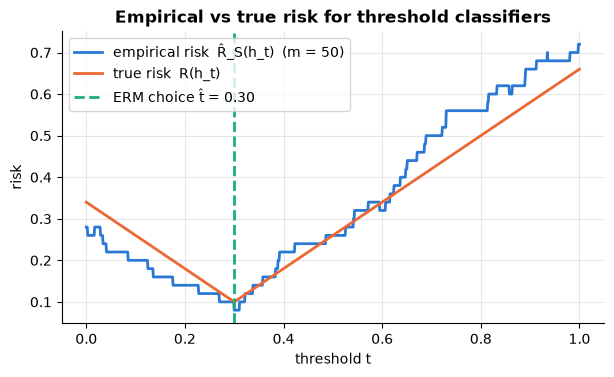

,m,mean excess risk R(ĥ) - R(h*),√m × excess
0,10,0.0932,0.2948
1,30,0.0335,0.1833
2,100,0.0110,0.1096
3,300,0.0031,0.0536
4,1000,0.0009,0.0276
5,3000,0.0001,0.0080


In [2]:
ETA, T_TRUE = 0.1, 0.3

def sample_threshold_data(m, r, eta=ETA, t_true=T_TRUE):
    x = r.random(m)
    y = (x >= t_true).astype(int)
    flip = r.random(m) < eta
    return x, np.where(flip, 1 - y, y)

def true_risk_threshold(t, eta=ETA, t_true=T_TRUE):
    return eta + (1 - 2 * eta) * np.abs(t - t_true)

def empirical_risks(x, y, ts):
    """Empirical 0-1 risk of h_t(x) = 1[x >= t] for every threshold t in ts (vectorised)."""
    preds = (x[None, :] >= ts[:, None]).astype(int)        # shape (len(ts), m)
    return (preds != y[None, :]).mean(axis=1)

ts = np.linspace(0, 1, 1001)
x, y = sample_threshold_data(50, rng)
emp = empirical_risks(x, y, ts)
t_hat = ts[np.argmin(emp)]
print(f"ERM threshold from 50 points: t_hat = {t_hat:.3f}; empirical risk = {emp.min():.3f}; "
      f"true risk = {true_risk_threshold(t_hat):.3f} (best possible = {ETA})")

plt.figure(figsize=(7, 3.8))
plt.plot(ts, emp, label="empirical risk  R̂_S(h_t)  (m = 50)")
plt.plot(ts, true_risk_threshold(ts), label="true risk  R(h_t)")
plt.axvline(t_hat, color=PALETTE[2], ls="--", label=f"ERM choice t̂ = {t_hat:.2f}")
plt.xlabel("threshold t"); plt.ylabel("risk"); plt.title("Empirical vs true risk for threshold classifiers")
plt.legend(); plt.show()

# excess risk of ERM as the sample grows (average over 300 repetitions)
rows = []
for m in [10, 30, 100, 300, 1000, 3000]:
    excess = []
    for rep in range(300):
        xr, yr = sample_threshold_data(m, np.random.default_rng(10_000 + rep * 7 + m))
        t_erm = ts[np.argmin(empirical_risks(xr, yr, ts))]
        excess.append(true_risk_threshold(t_erm) - ETA)
    rows.append({"m": m, "mean excess risk R(ĥ) - R(h*)": np.mean(excess), "√m × excess": np.sqrt(m) * np.mean(excess)})
pd.DataFrame(rows).round(4)

**What just happened?** The empirical risk curve is a noisy, jagged version of the true V-shaped risk; ERM picks the bottom of the *noisy* curve. The table shows the **estimation error** $R(\hat h) - R(h^\star)$ shrinking as $m$ grows. The approximation error is zero here, because the true rule is in the class. The last column is not constant: it keeps falling, so the excess risk shrinks *faster* than $1/\sqrt m$. That fits theory: here the probability of label 1 *jumps* at $x = 0.3$, so ERM can locate the jump at the fast rate $1/m$ (check: $m \times$ excess stays roughly constant until the threshold grid's resolution of 0.001 takes over). The uniform $O(1/\sqrt m)$ bounds of Sections 3–5 are worst-case rates and are often pessimistic.

⚠️ **Common mistake:** reporting the training error $\hat R_S(\hat h)$ as "the accuracy". Because $\hat h$ was *chosen* to make it small, it is a biased (optimistic) estimate of $R(\hat h)$. The rest of this notebook is about bounding that optimism.

## 2. The bias–variance decomposition

The test error of a model trained on random data splits into three pieces: noise you can never remove, error from the model being too simple, and error from the model being too jumpy.

**Set-up.** $y = f(x) + \varepsilon$ with $\mathbb E[\varepsilon] = 0$ and $\operatorname{Var}(\varepsilon) = \sigma^2$. A learning algorithm trained on a random sample $S$ outputs $\hat f_S$. Fix a test point $x$ and write $\bar f(x) = \mathbb E_S[\hat f_S(x)]$ (the *average* model over training sets).

**Derivation.** Expand the expected squared error, averaging over training sets $S$ and test noise $\varepsilon$:

$$\begin{aligned}
\mathbb E\big[(y - \hat f_S(x))^2\big] &= \mathbb E\big[(f(x) + \varepsilon - \hat f_S(x))^2\big] \\
&= \sigma^2 + \mathbb E\big[(f(x) - \hat f_S(x))^2\big] \qquad (\varepsilon \text{ is independent of } S \text{ with mean } 0)\\
&= \sigma^2 + \mathbb E\big[(f(x) - \bar f(x) + \bar f(x) - \hat f_S(x))^2\big] \\
&= \underbrace{\sigma^2}_{\text{noise}} + \underbrace{\big(f(x) - \bar f(x)\big)^2}_{\text{bias}^2} + \underbrace{\mathbb E\big[(\hat f_S(x) - \bar f(x))^2\big]}_{\text{variance}}
\end{aligned}$$

The cross term vanishes because $\mathbb E_S[\bar f(x) - \hat f_S(x)] = 0$. Averaging over test points $x$ gives the same identity for the expected test MSE.

**Simulation plan:**
- true function $f(x) = \sin(2\pi x)$, noise $\sigma = 0.3$, training sets of $m = 25$ points;
- fit polynomials of degree 0 to 12 by least squares;
- repeat over 300 independent training sets and measure each term directly;
- check that bias² + variance + noise equals the measured test MSE.

In [3]:
f_true = lambda x: np.sin(2 * np.pi * x)
SIGMA, M_BV, REPS = 0.3, 25, 300
x_test = np.linspace(0, 1, 200)
degrees = list(range(13))

def fit_poly(x, y, deg):
    """Least-squares polynomial fit in the Legendre basis on [-1, 1] (numerically stable)."""
    V = legendre.legvander(2 * x - 1, deg)
    coef, *_ = np.linalg.lstsq(V, y, rcond=None)
    return lambda xn: legendre.legvander(2 * xn - 1, deg) @ coef

preds = np.zeros((len(degrees), REPS, len(x_test)))
direct_mse = np.zeros(len(degrees))
r_bv = np.random.default_rng(1)
for rep in range(REPS):
    xs_ = r_bv.random(M_BV)
    ys_ = f_true(xs_) + SIGMA * r_bv.normal(size=M_BV)
    y_test_noisy = f_true(x_test) + SIGMA * r_bv.normal(size=len(x_test))   # fresh test noise
    for k, deg in enumerate(degrees):
        preds[k, rep] = fit_poly(xs_, ys_, deg)(x_test)
        direct_mse[k] += np.mean((y_test_noisy - preds[k, rep]) ** 2) / REPS

f_bar = preds.mean(axis=1)                                         # average model per degree
bias2 = ((f_bar - f_true(x_test)) ** 2).mean(axis=1)
variance = preds.var(axis=1).mean(axis=1)
bv = pd.DataFrame({"degree": degrees, "bias²": bias2, "variance": variance, "noise σ²": SIGMA**2,
                   "bias²+var+noise": bias2 + variance + SIGMA**2, "measured test MSE": direct_mse})
bv.round(4)

,degree,bias²,variance,noise σ²,bias²+var+noise,measured test MSE
0,0,0.4978,0.0237,0.09,0.6115,0.6095
1,1,0.2002,0.0247,0.09,0.3149,0.3132
2,2,0.2022,0.0618,0.09,0.3541,0.3533
3,3,0.0053,0.0242,0.09,0.1195,0.1189
4,4,0.0063,0.0436,0.09,0.1399,0.1390
5,5,0.0002,0.0606,0.09,0.1509,0.1495
6,6,0.0009,0.3363,0.09,0.4271,0.4266
7,7,0.0022,0.7263,0.09,0.8185,0.8168
8,8,0.0712,8.6878,0.09,8.8490,8.8378
9,9,0.6818,132.5882,0.09,133.3600,133.3537


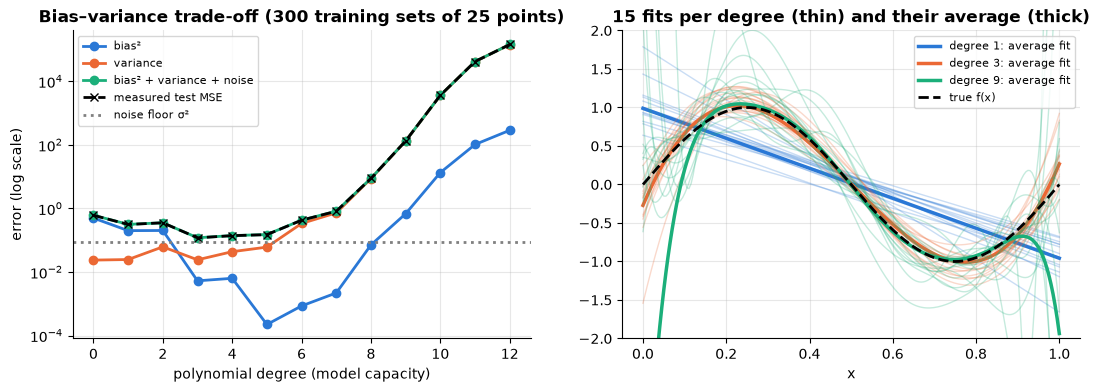

best degree = 3; at degree 0 bias² dominates (0.498); at degree 12 variance dominates (1.44e+05)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogy(degrees, bias2, "o-", label="bias²")
axes[0].semilogy(degrees, variance, "o-", label="variance")
axes[0].semilogy(degrees, bias2 + variance + SIGMA**2, "o-", label="bias² + variance + noise")
axes[0].semilogy(degrees, direct_mse, "x--", color="black", label="measured test MSE")
axes[0].axhline(SIGMA**2, color="gray", ls=":", label="noise floor σ²")
axes[0].set_xlabel("polynomial degree (model capacity)"); axes[0].set_ylabel("error (log scale)")
axes[0].set_title("Bias–variance trade-off (300 training sets of 25 points)"); axes[0].legend(fontsize=8)
for k, (deg, col) in enumerate(zip([1, 3, 9], PALETTE[:3])):
    for rep in range(15):
        axes[1].plot(x_test, preds[deg, rep], color=col, alpha=0.25, lw=1)
    axes[1].plot(x_test, f_bar[deg], color=col, lw=2.5, label=f"degree {deg}: average fit")
axes[1].plot(x_test, f_true(x_test), "k--", lw=2, label="true f(x)")
axes[1].set_ylim(-2, 2); axes[1].set_xlabel("x"); axes[1].set_title("15 fits per degree (thin) and their average (thick)")
axes[1].legend(fontsize=8); plt.show()
best = int(np.argmin(direct_mse))
print(f"best degree = {best}; at degree 0 bias² dominates ({bias2[0]:.3f}); at degree 12 variance dominates ({variance[12]:.3g})")
assert np.allclose(bias2 + variance + SIGMA**2, direct_mse, rtol=0.1)

**What just happened?**
- **Low degree** (0–1): the average fit cannot bend like a sine wave, so the bias is large and the variance tiny.
- **High degree** (9 and above, with only 25 points): individual fits swing wildly between training sets (huge variance). Those extreme swings near the edges of the data also pull the *average* fit away from the truth, so bias² rises again as well (see the table above). Variance is still by far the bigger term.
- The measured test MSE equals bias² + variance + noise up to Monte-Carlo error, confirming the derivation. The minimum is at a moderate degree (printed above), where the two error sources balance.
- No model can go below the noise floor $\sigma^2 = 0.09$.

**Complexity of the experiment:** $O(\text{REPS} \times \text{degrees} \times m\,d^2)$ for the least-squares fits. This is cheap here, but it shows why bias and variance are rarely measured directly in practice: you would need many independent training sets. Bootstrap resampling is the usual approximation.

🎓 **Exam / interview tip:** the decomposition is exact only for **squared loss**. For 0–1 loss there are several competing definitions (Domingos 2000; James 2003), and bias and variance interact rather than add. Also, "variance" here means variance over **training sets**, not the variance of the predictions across test inputs.

## 3. PAC learning with a finite hypothesis class

PAC learning makes "learning works" precise: with enough examples we will *probably* (with high confidence) get a model that is *approximately* correct (low error).

A class $\mathcal H$ is **PAC learnable** if there is an algorithm and a function $m_{\mathcal H}(\varepsilon, \delta)$ such that for every distribution $\mathcal D$ (realisable by $\mathcal H$) and every $\varepsilon, \delta \in (0, 1)$, given $m \ge m_{\mathcal H}(\varepsilon, \delta)$ i.i.d. examples, the output $\hat h$ satisfies

$$\Pr_S\big[R(\hat h) \le \varepsilon\big] \ge 1 - \delta.$$

$\varepsilon$ is the *accuracy* parameter ("approximately correct") and $\delta$ the *confidence* parameter ("probably").

**Theorem (finite class, realisable case).** If $\mathcal H$ is finite and contains a perfect hypothesis, any ERM (consistent) learner satisfies the PAC condition whenever

$$m \;\ge\; \frac{1}{\varepsilon}\Big(\ln|\mathcal H| + \ln\frac1\delta\Big).$$

**Proof sketch (a 3-line exam answer):**
1. A fixed "bad" hypothesis with $R(h) > \varepsilon$ is consistent with $m$ i.i.d. examples with probability $< (1 - \varepsilon)^m \le e^{-\varepsilon m}$.
2. By the union bound over at most $|\mathcal H|$ bad hypotheses, $\Pr[\text{some bad } h \text{ is consistent}] < |\mathcal H| e^{-\varepsilon m}$.
3. Set this $\le \delta$ and solve for $m$.

**Agnostic case** (no perfect hypothesis; a consequence of Hoeffding in Section 4): $m \ge \frac{\ln(2|\mathcal H|/\delta)}{2\varepsilon^2}$ guarantees $|\hat R_S(h) - R(h)| \le \varepsilon$ for **all** $h \in \mathcal H$ at once. Note the $1/\varepsilon^2$ instead of $1/\varepsilon$: noise makes learning quadratically harder.

**Experiment.** $\mathcal H$ = the 101 thresholds $t \in \{0, 0.01, \dots, 1\}$; the target is $t^\star = 0.37$ with no noise; $\varepsilon = \delta = 0.05$. The bound asks for $m \ge (\ln 101 + \ln 20)/0.05 \approx 152.2$, so $m = 153$. To stress-test the bound we let ERM pick the **worst** consistent hypothesis, and estimate $\Pr[R(\hat h) > \varepsilon]$ over 5,000 repetitions for several $m$.

In [5]:
H_grid = np.round(np.arange(101) / 100, 2)          # |H| = 101 thresholds
T_STAR, EPS, DELTA = 0.37, 0.05, 0.05
m_bound = ceil((np.log(len(H_grid)) + np.log(1 / DELTA)) / EPS)
print(f"PAC bound (realisable): m >= (ln {len(H_grid)} + ln {1/DELTA:.0f}) / {EPS} = {m_bound}")

def worst_consistent_error(m, r, trials):
    """For each trial: draw m clean points, find the consistent thresholds, return the
    largest true error among them (true error of h_t is |t - T_STAR| under Uniform(0,1))."""
    x = r.random((trials, m))
    pos_min = np.where(x >= T_STAR, x, np.inf).min(axis=1)       # smallest positive point
    neg_max = np.where(x < T_STAR, x, -np.inf).max(axis=1)       # largest negative point
    # t is consistent iff neg_max < t <= pos_min
    cons = (H_grid[None, :] > neg_max[:, None]) & (H_grid[None, :] <= pos_min[:, None])
    errs = np.where(cons, np.abs(H_grid[None, :] - T_STAR), -1.0)
    return errs.max(axis=1)

rows = []
for m in [10, 20, 40, 80, m_bound, 300]:
    worst = worst_consistent_error(m, np.random.default_rng(m), 5000)
    rows.append({"m": m, "empirical P[R(ĥ) > ε]": (worst > EPS).mean(),
                 "union bound |H|(1-ε)^m": min(1.0, len(H_grid) * (1 - EPS) ** m)})
pac = pd.DataFrame(rows)
pac

PAC bound (realisable): m >= (ln 101 + ln 20) / 0.05 = 153


,m,empirical P[R(ĥ) > ε],union bound |H|(1-ε)^m
0,10,0.8016,1.000000
1,20,0.5018,1.000000
2,40,0.1572,1.000000
3,80,0.0142,1.000000
4,153,0.0002,0.039449
5,300,0.0000,0.000021


In [6]:
# Agnostic case: label noise 10%; is sup_h |R̂(h) - R(h)| <= ε for all 101 hypotheses at once?
m_agn = ceil(np.log(2 * len(H_grid) / DELTA) / (2 * EPS**2))
print(f"agnostic bound: m >= ln(2|H|/δ) / (2ε²) = {m_agn}")
fails = 0
r_ag = np.random.default_rng(7)
TR = 400
for _ in range(TR):
    xa, ya = sample_threshold_data(m_agn, r_ag, eta=0.1, t_true=T_STAR)
    gap = np.abs(empirical_risks(xa, ya, H_grid) - true_risk_threshold(H_grid, 0.1, T_STAR)).max()
    fails += gap > EPS
print(f"empirical P[sup_h |R̂ - R| > ε] at m = {m_agn}: {fails / TR:.4f}   (guarantee: <= {DELTA})")

agnostic bound: m >= ln(2|H|/δ) / (2ε²) = 1661


empirical P[sup_h |R̂ - R| > ε] at m = 1661: 0.0000   (guarantee: <= 0.05)


**What just happened?** The empirical failure probability is always **below** the bound, and usually far below it. At the bound's $m = 153$ the observed failure rate is essentially zero, against a guaranteed $\le 0.05$. In the agnostic case all 101 empirical risks were within $\varepsilon$ of the true ones in every repetition. Bounds built from the union bound are **worst-case over all distributions and all ways of breaking ties**, so for a specific easy distribution they are conservative. That is a feature (a guarantee you can rely on), but it also means the numbers are pessimistic planning tools.

**Complexity:** the bound grows only **logarithmically** in $|\mathcal H|$. Doubling the number of hypotheses costs just $\ln 2/\varepsilon$ more examples. This is why a class of $2^{64}$ hypotheses (e.g. any rule describable in 64 bits) is still learnable from a moderate sample: $\ln 2^{64} \approx 44$.

## 4. Concentration: Hoeffding's inequality and uniform convergence

Averages of many independent random numbers almost never stray far from their expected value, and we can say exactly how unlikely a big deviation is.

**Hoeffding's inequality.** If $Z_1, \dots, Z_m$ are independent with values in $[a, b]$ and $\bar Z = \frac1m \sum Z_i$, then for every $\varepsilon > 0$

$$\Pr\big[|\bar Z - \mathbb E\bar Z| \ge \varepsilon\big] \le 2\exp\Big(-\frac{2m\varepsilon^2}{(b - a)^2}\Big).$$

For a **fixed** hypothesis $h$ and 0–1 loss, $Z_i = \mathbb 1[h(x_i) \ne y_i] \in [0, 1]$, so the training error of a fixed $h$ is within $\varepsilon$ of its true error except with probability $2e^{-2m\varepsilon^2}$.

**Uniform convergence.** ERM does not use a fixed $h$; it chooses $h$ *after* seeing the data. So we need $\sup_{h \in \mathcal H} |\hat R_S(h) - R(h)|$ to be small, i.e. **all** empirical risks must be close to their true values simultaneously. If that holds, ERM is near-optimal: $R(\hat h) \le R(h^\star) + 2\sup_h|\hat R_S(h) - R(h)|$.

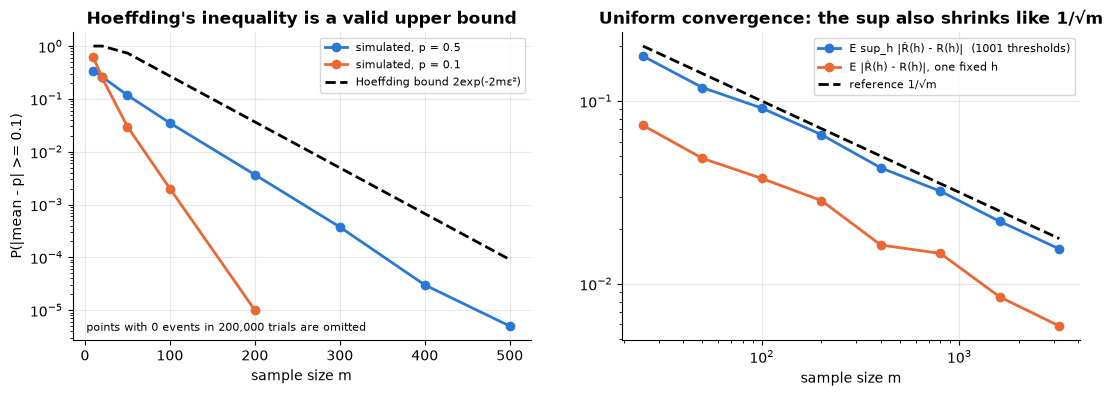

ratio sup-deviation / single-deviation: [2.39 2.44 2.43 2.29 2.64 2.19 2.59 2.64]


In [7]:
eps_h = 0.1
ms = np.array([10, 20, 50, 100, 200, 300, 400, 500])
r_h = np.random.default_rng(3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for p, col in [(0.5, PALETTE[0]), (0.1, PALETTE[1])]:
    emp_prob = np.array([(np.abs(r_h.binomial(m, p, size=200_000) / m - p) >= eps_h).mean() for m in ms])
    seen = emp_prob > 0                       # zero events in 200,000 trials cannot be drawn on a log axis
    axes[0].semilogy(ms[seen], emp_prob[seen], "o-", color=col, label=f"simulated, p = {p}")
axes[0].semilogy(ms, np.minimum(1, 2 * np.exp(-2 * ms * eps_h**2)), "k--", label="Hoeffding bound 2exp(-2mε²)")
axes[0].set_xlabel("sample size m"); axes[0].set_ylabel(f"P(|mean - p| >= {eps_h})")
axes[0].set_title("Hoeffding's inequality is a valid upper bound"); axes[0].legend(fontsize=8)
axes[0].text(0.03, 0.03, "points with 0 events in 200,000 trials are omitted", transform=axes[0].transAxes, fontsize=8)

# uniform convergence for the 1001 thresholds vs a single fixed threshold
ms_u = np.array([25, 50, 100, 200, 400, 800, 1600, 3200])
sup_dev, single_dev = [], []
for m in ms_u:
    s_, f_ = [], []
    for rep in range(100):
        xu, yu = sample_threshold_data(m, np.random.default_rng(50_000 + rep + 7 * m))
        dev = np.abs(empirical_risks(xu, yu, ts) - true_risk_threshold(ts))
        s_.append(dev.max()); f_.append(dev[500])            # dev[500] is the fixed threshold t = 0.5
    sup_dev.append(np.mean(s_)); single_dev.append(np.mean(f_))
axes[1].loglog(ms_u, sup_dev, "o-", label="E sup_h |R̂(h) - R(h)|  (1001 thresholds)")
axes[1].loglog(ms_u, single_dev, "o-", label="E |R̂(h) - R(h)|, one fixed h")
axes[1].loglog(ms_u, 1 / np.sqrt(ms_u), "k--", label="reference 1/√m")
axes[1].set_xlabel("sample size m"); axes[1].set_title("Uniform convergence: the sup also shrinks like 1/√m")
axes[1].legend(fontsize=8); plt.show()
print("ratio sup-deviation / single-deviation:", np.round(np.array(sup_dev) / np.array(single_dev), 2))

**What just happened?**
- **Left:** the simulated deviation probabilities always lie below Hoeffding's curve. The bound is tightest for $p = 0.5$ (maximum variance); for $p = 0.1$ the true probability is much smaller, because Hoeffding ignores the variance. Bernstein's inequality uses it.
- **Right:** the worst deviation over *all 1001 thresholds* is larger than the deviation of one fixed threshold, by a roughly constant factor (printed above), but it still shrinks at the $1/\sqrt m$ rate. This is uniform convergence: although there are infinitely many thresholds, they behave like a small class. The next section explains why: the class has VC dimension 1.

## 5. VC dimension, the growth function and the VC bound

The VC dimension measures a model family's flexibility by asking: what is the largest group of points it can label in *every* possible way?

Finite-class bounds use $\ln|\mathcal H|$, which is useless for infinite classes such as all lines in the plane. Vapnik and Chervonenkis replaced $|\mathcal H|$ by the number of *different labelings* $\mathcal H$ can produce on $m$ points.

- **Restriction:** $\mathcal H_C$ = the set of label vectors $(h(c_1), \dots, h(c_m))$ for $h \in \mathcal H$, on a set $C$ of $m$ points.
- $\mathcal H$ **shatters** $C$ if it realises all $2^m$ labelings of $C$.
- The **VC dimension** $d_{VC}(\mathcal H)$ is the size of the **largest** set that $\mathcal H$ shatters. To prove $d_{VC} = d$, show (1) *some* set of $d$ points is shattered, and (2) *no* set of $d + 1$ points is shattered.
- The **growth function** $\Pi_{\mathcal H}(m) = \max_{|C| = m} |\mathcal H_C|$.
- **Sauer–Shelah lemma:** if $d_{VC} = d$, then $\Pi_{\mathcal H}(m) \le \sum_{i=0}^d \binom mi \le \big(\frac{em}{d}\big)^d$. That is *polynomial* in $m$, not $2^m$, and this is what makes infinite classes learnable.

| Class | VC dimension | Why $d+1$ points fail |
|---|---|---|
| thresholds $\mathbb 1[x \ge t]$ on $\mathbb R$ | 1 | labeling $(+, -)$ for $x_1 < x_2$ |
| intervals $\mathbb 1[a \le x \le b]$ | 2 | labeling $(+, -, +)$ |
| half-planes in $\mathbb R^2$ | 3 | 4 points: XOR pattern, or one point inside the triangle of the others (Radon's theorem) |
| half-spaces in $\mathbb R^d$ | $d + 1$ | Radon's theorem |
| axis-aligned rectangles in $\mathbb R^2$ | 4 | of 5 points, label the leftmost/rightmost/top/bottom ones $+$ and the remaining one $-$ |
| $\{\operatorname{sign}(\sin(\omega x))\}$ | $\infty$ | one parameter, infinite capacity: VC dim ≠ number of parameters |

Below we check shattering by brute force: enumerate all $2^m$ labelings and test whether each one is realisable.

In [8]:
def shatters(points, realisable):
    """True if every one of the 2^m labelings of `points` is realisable by the class."""
    m = len(points)
    return all(realisable(points, np.array(lab)) for lab in itertools.product([0, 1], repeat=m))

def count_labelings(points, realisable):
    """|H_C|: how many of the 2^m labelings the class can realise on these points."""
    return sum(realisable(points, np.array(lab)) for lab in itertools.product([0, 1], repeat=len(points)))

# --- intervals on the line: realisable iff the positives form one contiguous block (or there are none)
def interval_ok(pts, lab):
    order = lab[np.argsort(pts)]
    idx = np.nonzero(order)[0]
    return len(idx) == 0 or order[idx[0]:idx[-1] + 1].all()

# --- half-planes in R^2: realisable iff linearly separable; check feasibility of y_i (w.x_i + b) >= 1 with an LP
def halfplane_ok(pts, lab):
    if lab.all() or not lab.any():
        return True
    s = 2 * lab - 1
    A_ub = -s[:, None] * np.hstack([pts, np.ones((len(pts), 1))])    # -y_i [x_i, 1] . [w, b] <= -1
    res = linprog(np.zeros(3), A_ub=A_ub, b_ub=-np.ones(len(pts)), bounds=[(None, None)] * 3, method="highs")
    return res.status == 0

# --- axis-aligned rectangles: realisable iff the bounding box of the positives contains no negative
def rect_ok(pts, lab):
    if not lab.any():
        return True
    P = pts[lab == 1]; lo, hi = P.min(0), P.max(0)
    inside = np.all((pts >= lo) & (pts <= hi), axis=1)
    return not np.any(inside & (lab == 0))

print("intervals, 2 points  :", shatters(np.array([0.2, 0.7]), interval_ok))
print("intervals, 3 points  :", shatters(np.array([0.2, 0.5, 0.7]), interval_ok), "  -> d_VC(intervals) = 2")
tri = np.array([[0, 0], [1, 0], [0, 1]], dtype=float)
print("half-planes, triangle:", shatters(tri, halfplane_ok))
square = np.array([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=float)
print("half-planes, square  :", shatters(square, halfplane_ok), " (the XOR labeling fails)")
diamond = np.array([[0, 1], [1, 0], [0, -1], [-1, 0]], dtype=float)
print("rectangles, diamond  :", shatters(diamond, rect_ok))

r_vc = np.random.default_rng(11)
hp4 = sum(shatters(r_vc.normal(size=(4, 2)), halfplane_ok) for _ in range(100))
rc5 = sum(shatters(r_vc.normal(size=(5, 2)), rect_ok) for _ in range(300))
print(f"random 4-point sets shattered by half-planes: {hp4}/100;  random 5-point sets shattered by rectangles: {rc5}/300")

intervals, 2 points  : True
intervals, 3 points  : False   -> d_VC(intervals) = 2
half-planes, triangle: True
half-planes, square  : False  (the XOR labeling fails)
rectangles, diamond  : True


random 4-point sets shattered by half-planes: 0/100;  random 5-point sets shattered by rectangles: 0/300


**What just happened?** The brute-force checks reproduce the table. Intervals shatter 2 points but not 3. Half-planes shatter a triangle but not a square, and not *any* of 100 random 4-point sets. Rectangles shatter a diamond, but none of 300 random 5-point sets. Random sets are only evidence, not a proof; the proofs are in the table's last column.

Now the growth function. For half-planes on $m$ points in general position, **Cover's theorem (1965)** gives the exact count $2\sum_{i=0}^{2}\binom{m-1}{i} = m^2 - m + 2$; for intervals it is $\binom{m+1}{2} + 1$. Let's count labelings by brute force and compare with $2^m$ and the Sauer bound.

In [9]:
rows = []
for m in range(1, 9):
    pts2 = r_vc.normal(size=(m, 2))                              # random points: general position w.p. 1
    pts1 = np.sort(r_vc.random(m))
    hp, iv = count_labelings(pts2, halfplane_ok), count_labelings(pts1, interval_ok)
    rows.append({"m": m, "2^m": 2**m,
                 "half-planes (counted)": hp, "Cover m²-m+2": m * m - m + 2, "Sauer bound d=3": sum(comb(m, i) for i in range(4)),
                 "intervals (counted)": iv, "C(m+1,2)+1": comb(m + 1, 2) + 1, "Sauer bound d=2": sum(comb(m, i) for i in range(3))})
growth = pd.DataFrame(rows)
assert (growth["half-planes (counted)"] == growth["Cover m²-m+2"]).all()
assert (growth["intervals (counted)"] == growth["C(m+1,2)+1"]).all()
growth

,m,2^m,half-planes (counted),Cover m²-m+2,Sauer bound d=3,intervals (counted),"C(m+1,2)+1",Sauer bound d=2
0,1,2,2,2,2,2,2,2
1,2,4,4,4,4,4,4,4
2,3,8,8,8,8,7,7,7
3,4,16,14,14,15,11,11,11
4,5,32,22,22,26,16,16,16
5,6,64,32,32,42,22,22,22
6,7,128,44,44,64,29,29,29
7,8,256,58,58,93,37,37,37


**What just happened?** Up to $m = d_{VC}$ the class realises all $2^m$ labelings: 8 for half-planes at $m = 3$, 4 for intervals at $m = 2$. After that the count grows only polynomially; at $m = 8$, half-planes realise 58 of the 256 labelings. The counts match Cover's formula exactly and stay below the Sauer bound.

### The VC generalisation bound

Combining the growth function with a symmetrisation ("ghost sample") argument gives the VC bound. In the form used by Abu-Mostafa, Magdon-Ismail and Lin (*Learning From Data*, 2012), with probability at least $1 - \delta$, for **all** $h \in \mathcal H$:

$$R(h) \;\le\; \hat R_S(h) + \sqrt{\frac{8}{m}\ln\frac{4\,\Pi_{\mathcal H}(2m)}{\delta}}, \qquad \Pi_{\mathcal H}(2m) \le (2m)^{d_{VC}} + 1.$$

Solving "gap $\le \varepsilon$" for $m$ gives a **sample-complexity** estimate. It has no closed form, so we iterate $m \leftarrow \frac{8}{\varepsilon^2}\ln\frac{4((2m)^d + 1)}{\delta}$ to a fixed point.

 d_VC  m needed (ε=0.1, δ=0.1)  ratio m / d_VC
    1                    10947    10947.000000
    3                    29300     9766.666667
    5                    48916     9783.200000
   10                   100652    10065.200000
   20                   210130    10506.500000
   50                   560113    11202.260000


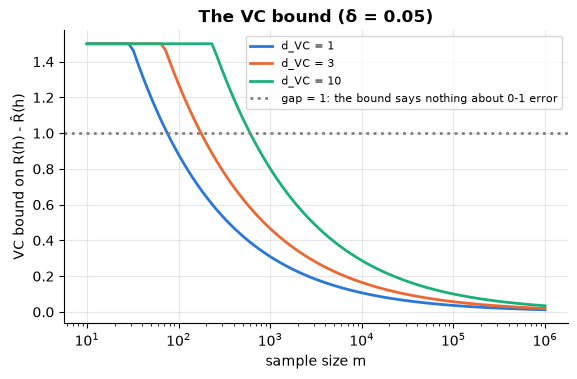

In [10]:
def vc_gap(m, d, delta):
    return np.sqrt(8 / m * np.log(4 * ((2 * m) ** d + 1) / delta))

def vc_sample_size(d, eps, delta, m=1000.0):
    for _ in range(200):                                          # fixed-point iteration
        m = 8 / eps**2 * np.log(4 * ((2 * m) ** d + 1) / delta)
    return int(np.ceil(m))

table = pd.DataFrame([{"d_VC": d, "m needed (ε=0.1, δ=0.1)": vc_sample_size(d, 0.1, 0.1),
                       "ratio m / d_VC": vc_sample_size(d, 0.1, 0.1) / d} for d in [1, 3, 5, 10, 20, 50]])
print(table.to_string(index=False))

mm = np.logspace(1, 6, 100)
plt.figure(figsize=(6.5, 3.8))
for d in [1, 3, 10]:
    plt.semilogx(mm, np.minimum(vc_gap(mm, d, 0.05), 1.5), label=f"d_VC = {d}")
plt.axhline(1.0, color="gray", ls=":", label="gap = 1: the bound says nothing about 0-1 error")
plt.xlabel("sample size m"); plt.ylabel("VC bound on R(h) - R̂(h)"); plt.title("The VC bound (δ = 0.05)")
plt.legend(fontsize=8); plt.show()

**What just happened?** For $d_{VC} = 3$ the bound asks for about 29,000 examples to guarantee a gap of 0.1 with 90% confidence. The required $m$ grows roughly linearly in $d_{VC}$, about 10,000 examples per unit of VC dimension at this accuracy. Practitioners use the much looser rule of thumb "$m \ge 10 \times d_{VC}$", which works in practice because the bound is worst-case over *all* distributions. The plot shows the bound is **vacuous** (above 1) for small samples. Its value is in the *shape* of the dependence on $m$ and $d$, not in its constants.

**The fundamental theorem of statistical learning:** for binary classification with 0–1 loss, the following are equivalent:
1. $\mathcal H$ has uniform convergence;
2. ERM is a PAC learner for $\mathcal H$ (agnostic or realisable);
3. $\mathcal H$ is PAC learnable;
4. $d_{VC}(\mathcal H) < \infty$.

The sample complexity is $\Theta\big(\frac{d + \ln(1/\delta)}{\varepsilon}\big)$ (realisable) or $\Theta\big(\frac{d + \ln(1/\delta)}{\varepsilon^2}\big)$ (agnostic). So VC dimension *exactly characterises* learnability.

⚠️ **Common mistake:** "VC dimension = number of parameters". It holds for linear classifiers ($d + 1$ parameters, VC $= d + 1$), but $\operatorname{sign}(\sin(\omega x))$ has one parameter and infinite VC dimension. For ReLU networks with $W$ weights and $L$ layers, the VC dimension is $\Theta(WL\log W)$ (Bartlett et al., 2019).

## 6. Rademacher complexity

Rademacher complexity measures how well a model family can fit pure coin-flip noise on *your* data. The better it fits noise, the less you should trust its training score.

Let $\sigma_1, \dots, \sigma_m$ be independent **Rademacher variables** (each $\pm1$ with probability ½). The **empirical Rademacher complexity** of a real-valued class $\mathcal F$ on a sample $S = (x_1, \dots, x_m)$ is

$$\hat{\mathfrak R}_S(\mathcal F) = \mathbb E_\sigma\Big[\sup_{f \in \mathcal F}\frac1m\sum_{i=1}^m \sigma_i f(x_i)\Big].$$

Read it as: *draw random labels $\sigma$; how well can the best $f$ in the class correlate with them?* Unlike the VC dimension it depends on the data and works for real-valued (regression, margin) classes.

**Generalisation bound** (Mohri et al., 2018, Theorem 3.3, for losses in $[0, 1]$): with probability $\ge 1 - \delta$, for all $f$,

$$R(f) \le \hat R_S(f) + 2\hat{\mathfrak R}_S(\ell \circ \mathcal F) + 3\sqrt{\frac{\ln(2/\delta)}{2m}}.$$

**Norm-bounded linear models.** For $\mathcal F_B = \{x \mapsto w^\top x : \lVert w\rVert_2 \le B\}$, Cauchy–Schwarz gives the supremum exactly: $\sup_{\lVert w\rVert \le B} w^\top v = B\lVert v\rVert$ with $v = \frac1m\sum_i\sigma_i x_i$. Hence

$$\hat{\mathfrak R}_S(\mathcal F_B) = \frac Bm\,\mathbb E_\sigma\Big\lVert\sum_i \sigma_i x_i\Big\rVert_2 \;\le\; \frac Bm\sqrt{\sum_i\lVert x_i\rVert^2} \;\le\; \frac{B \max_i\lVert x_i\rVert}{\sqrt m}.$$

The complexity grows **linearly with the weight norm $B$** and shrinks like $1/\sqrt m$, and it does **not depend on the dimension**. This is the theoretical reason why weight decay (keeping $\lVert w\rVert$ small) controls overfitting even in very high dimensions.

In [11]:
def rademacher_linear(X, B, n_sigma=2000, seed=0):
    """Monte-Carlo estimate of the empirical Rademacher complexity of {w.x : ||w|| <= B}."""
    r = np.random.default_rng(seed)
    sig = r.choice([-1.0, 1.0], size=(n_sigma, len(X)))
    return B * np.linalg.norm(sig @ X, axis=1).mean() / len(X)     # exact sup via Cauchy-Schwarz

# sanity check of the closed-form sup: random unit vectors never beat the Cauchy-Schwarz maximiser
Xr = rng.normal(size=(100, 10)); sig = rng.choice([-1.0, 1.0], 100)
v = sig @ Xr / 100
W = rng.normal(size=(20000, 10)); W /= np.linalg.norm(W, axis=1, keepdims=True)
print(f"best of 20,000 random unit w: {np.max(W @ v):.4f}  <=  closed form ||v|| = {np.linalg.norm(v):.4f}")

rows = []
for m in [20, 100, 500, 2000]:
    for B in [0.5, 1, 2, 4]:
        Xm = np.random.default_rng(m).normal(size=(m, 10))
        rows.append({"m": m, "B": B, "Rademacher (MC)": rademacher_linear(Xm, B),
                     "bound B·sqrt(Σ||x||²)/m": B * np.sqrt((Xm**2).sum()) / m})
rad = pd.DataFrame(rows)
rad.pivot(index="m", columns="B", values="Rademacher (MC)").round(4)

best of 20,000 random unit w: 0.4138  <=  closed form ||v|| = 0.4429


B,0.5,1.0,2.0,4.0
m,,,,
20,0.3696,0.7393,1.4785,2.9571
100,0.1548,0.3097,0.6193,1.2386
500,0.0696,0.1392,0.2785,0.5569
2000,0.0340,0.0681,0.1362,0.2724


In [12]:
# The finite-class view: thresholds on m points realise only m+1 labelings, so Massart's lemma
# gives R <= sqrt(2 ln(m+1) / m). Compute the empirical Rademacher complexity exactly by enumeration.
def rademacher_thresholds(m, n_sigma=3000, seed=0):
    r = np.random.default_rng(seed)
    x = np.sort(r.random(m))
    # all m+1 distinct behaviours of 1[x >= t] mapped to +-1
    behaviours = np.array([np.where(np.arange(m) >= k, 1.0, -1.0) for k in range(m + 1)])
    sig = r.choice([-1.0, 1.0], size=(n_sigma, m))
    return (sig @ behaviours.T / m).max(axis=1).mean()

rows = [{"m": m, "Rademacher(thresholds)": rademacher_thresholds(m), "Massart sqrt(2 ln(m+1)/m)": np.sqrt(2 * np.log(m + 1) / m)}
        for m in [10, 50, 200, 1000]]
pd.DataFrame(rows).round(4)

,m,Rademacher(thresholds),Massart sqrt(2 ln(m+1)/m)
0,10,0.4155,0.6925
1,50,0.2049,0.3966
2,200,0.1071,0.2303
3,1000,0.0496,0.1175


**What just happened?**
- The first check confirms the closed-form supremum: no random unit vector beats $\lVert v \rVert$.
- The pivot table shows the Rademacher complexity of norm-bounded linear models scaling **linearly in $B$** (each column is double the previous one) and shrinking like $1/\sqrt m$ down the rows (from $m = 20$ to $m = 2000$ it falls by about $\sqrt{100} = 10$).
- For thresholds, the exact enumeration sits comfortably below Massart's bound. Both shrink as $m$ grows: a class with only polynomially many behaviours cannot fit random labels on a large sample.

## 7. Regularisation, structural risk minimisation and margins

Regularisation is how we turn the capacity dial in practice: instead of picking a smaller model family, we penalise large or complicated models.

### 7.1 Regularisation as capacity control

Ridge regression minimises $\lVert Xw - y\rVert^2 + \lambda\lVert w\rVert^2$. Equivalently (by Lagrangian duality; see [`14_Mathematics/12_convex_optimization_and_duality`](../../14_Mathematics/12_convex_optimization_and_duality.ipynb)), it minimises the squared error subject to $\lVert w \rVert \le B(\lambda)$. By Section 6, a smaller $B$ means smaller Rademacher complexity. A related measure is the **effective degrees of freedom** $\mathrm{df}(\lambda) = \sum_j \frac{s_j^2}{s_j^2 + \lambda}$ ($s_j$ are the singular values of $X$), which falls smoothly from the number of features (at $\lambda = 0$) to 0.

In [13]:
# degree-12 polynomial features on 25 noisy sine points; vary the ridge penalty.
# Average over 200 independent training sets (as in Section 2) so that one lucky sample can't mislead us.
lams7 = [0, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
x7t = np.linspace(0, 1, 500); V7t = legendre.legvander(2 * x7t - 1, 12)
stats = np.zeros((len(lams7), 4))
r7 = np.random.default_rng(21)
for rep in range(200):
    x7 = r7.random(25); y7 = f_true(x7) + SIGMA * r7.normal(size=25)
    y7t = f_true(x7t) + SIGMA * r7.normal(size=len(x7t))
    V7 = legendre.legvander(2 * x7 - 1, 12)
    s_vals = np.linalg.svd(V7, compute_uv=False)
    for i, lam in enumerate(lams7):
        w = np.linalg.lstsq(V7, y7, rcond=None)[0] if lam == 0 else np.linalg.solve(V7.T @ V7 + lam * np.eye(13), V7.T @ y7)
        stats[i] += [(s_vals**2 / (s_vals**2 + lam)).sum(), np.linalg.norm(w),
                     np.mean((V7 @ w - y7) ** 2), np.mean((V7t @ w - y7t) ** 2)]
stats /= 200
ridge_tab = pd.DataFrame(stats, columns=["effective df", "mean ||w||", "train MSE", "test MSE"])
ridge_tab.insert(0, "λ", lams7)
ridge_tab.round(4)

,λ,effective df,mean ||w||,train MSE,test MSE
0,0.0000,13.0000,163.2671,0.0449,88107.4947
1,0.0001,12.5556,7.4397,0.0462,10.8633
2,0.0010,12.2263,3.6377,0.0472,1.4437
3,0.0100,11.6849,2.2011,0.0484,0.3220
4,0.1000,10.4492,1.6956,0.0512,0.1560
5,1.0000,7.2103,1.2795,0.0717,0.1369
6,10.0000,2.7128,0.5446,0.2607,0.3085
7,100.0000,0.4928,0.0927,0.5258,0.5339


**What just happened?** Averaged over 200 training sets, as $\lambda$ grows the weight norm and the effective degrees of freedom fall, and the training error rises. The test error falls by orders of magnitude, from the enormous unregularised value (the exploding variance of Section 2), to a minimum at a moderate $\lambda$, then rises again as bias takes over. The same degree-12 polynomial goes from useless to good: **capacity is controlled by the norm, not just by the number of parameters**.

### 7.2 Structural risk minimisation (SRM)

**SRM** (Vapnik) picks a nested sequence $\mathcal H_1 \subset \mathcal H_2 \subset \cdots$ and minimises *training error + complexity penalty* over $k$, instead of training error alone. To make the guarantee hold for all $k$ at once, class $k$ gets confidence $\delta_k = \delta / (k(k+1))$, so that $\sum_k \delta_k \le \delta$.

**A clean example where everything is computable.** $x \sim U(0, 1)$, $P(y = 1 \mid x) = 0.5 + 0.4\sin(3\pi x)$. $\mathcal H_k$ = classifiers that are constant on each of $k$ equal-width bins.
- ERM within $\mathcal H_k$ is just majority vote per bin.
- $d_{VC}(\mathcal H_k) = k$: one point per bin can be labelled freely; $k + 1$ points put two in the same bin (pigeonhole).
- The empirical Rademacher complexity is exactly $\mathbb E_\sigma \frac1m\sum_{\text{bins}}\big|\sum_{i \in \text{bin}}\sigma_i\big|$, because each bin can match the sign of its own sum.

We compare three ways to choose $k$:
1. SRM with the **VC** penalty;
2. SRM with the data-dependent **Rademacher** penalty (Mohri et al., Thm 3.5: $R \le \hat R + \hat{\mathfrak R}_S(\mathcal H) + 3\sqrt{\ln(2/\delta_k)/(2m)}$ for $\pm1$-valued classes);
3. a **validation set**.

Then we score each choice by its true risk.

Bayes risk = 0.2454
best in hindsight (oracle)     k =  3   true risk = 0.2454
SRM, VC penalty                k =  1   true risk = 0.4151
SRM, Rademacher penalty        k =  3   true risk = 0.2454
validation set                 k = 31   true risk = 0.2514
ERM over all k (train err)     k = 39   true risk = 0.2528


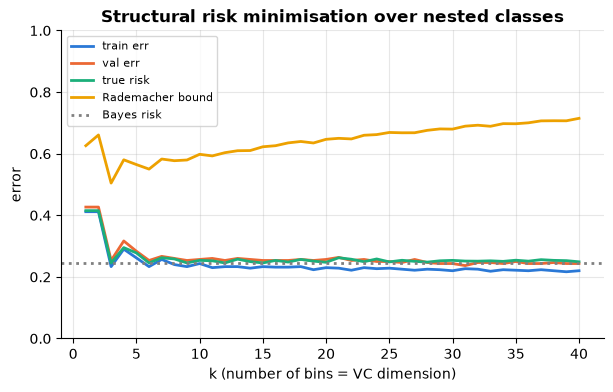

In [14]:
p_y = lambda x: 0.5 + 0.4 * np.sin(3 * np.pi * x)
grid_x = (np.arange(200_000) + 0.5) / 200_000                     # fine grid to integrate the true risk
bayes_risk = np.mean(np.minimum(p_y(grid_x), 1 - p_y(grid_x)))

def fit_bins(x, y, k):
    """ERM in H_k: majority label in each of k equal bins (ties -> 1)."""
    b = np.minimum((x * k).astype(int), k - 1)
    ones = np.bincount(b, weights=y, minlength=k); n = np.bincount(b, minlength=k)
    return (ones >= n / 2).astype(int)                            # empty bins -> label 1

def true_risk_bins(labels, k):
    b = np.minimum((grid_x * k).astype(int), k - 1)
    pred = labels[b]
    return np.mean(np.where(pred == 1, 1 - p_y(grid_x), p_y(grid_x)))

def emp_rademacher_bins(x, k, n_sigma=500, seed=0):
    r = np.random.default_rng(seed)
    b = np.minimum((x * k).astype(int), k - 1)
    sig = r.choice([-1.0, 1.0], size=(n_sigma, len(x)))
    sums = np.stack([np.bincount(b, weights=s, minlength=k) for s in sig])   # per-bin sums of sigma
    return np.abs(sums).sum(axis=1).mean() / len(x)

r8 = np.random.default_rng(5)
m_tr, m_val, delta = 600, 300, 0.05
xtr = r8.random(m_tr); ytr = (r8.random(m_tr) < p_y(xtr)).astype(int)
xva = r8.random(m_val); yva = (r8.random(m_val) < p_y(xva)).astype(int)
rows = []
for k in range(1, 41):
    lab = fit_bins(xtr, ytr, k)
    b_tr = np.minimum((xtr * k).astype(int), k - 1); b_va = np.minimum((xva * k).astype(int), k - 1)
    dk = delta / (k * (k + 1))
    rows.append({"k": k, "train err": np.mean(lab[b_tr] != ytr), "val err": np.mean(lab[b_va] != yva),
                 "true risk": true_risk_bins(lab, k),
                 "VC bound": np.mean(lab[b_tr] != ytr) + vc_gap(m_tr, k, dk),
                 "Rademacher bound": np.mean(lab[b_tr] != ytr) + emp_rademacher_bins(xtr, k) + 3 * np.sqrt(np.log(2 / dk) / (2 * m_tr))})
srm = pd.DataFrame(rows)
choice = {"best in hindsight (oracle)": srm.loc[srm["true risk"].idxmin(), "k"],
          "SRM, VC penalty": srm.loc[srm["VC bound"].idxmin(), "k"],
          "SRM, Rademacher penalty": srm.loc[srm["Rademacher bound"].idxmin(), "k"],
          "validation set": srm.loc[srm["val err"].idxmin(), "k"],
          "ERM over all k (train err)": srm.loc[srm["train err"].idxmin(), "k"]}
print(f"Bayes risk = {bayes_risk:.4f}")
for name, k in choice.items():
    print(f"{name:30s} k = {k:2d}   true risk = {srm.loc[srm.k == k, 'true risk'].item():.4f}")

plt.figure(figsize=(7, 4))
for col in ["train err", "val err", "true risk", "Rademacher bound"]:
    plt.plot(srm.k, srm[col], label=col)
plt.axhline(bayes_risk, color="gray", ls=":", label="Bayes risk")
plt.xlabel("k (number of bins = VC dimension)"); plt.ylabel("error"); plt.ylim(0, 1)
plt.title("Structural risk minimisation over nested classes"); plt.legend(fontsize=8); plt.show()

**What just happened?** Training error keeps falling as $k$ grows, so "ERM over all $k$" picks a very fine class ($k = 39$) and overfits slightly. The comparison shows three behaviours:
- The **VC penalty** is so large at $m = 600$ that SRM chooses $k = 1$ (a constant classifier), far too simple.
- The data-dependent **Rademacher penalty** is tighter and picks $k = 3$. That is exactly the Bayes classifier: $\sin(3\pi x)$ changes sign at $x = 1/3$ and $2/3$, so three bins can represent the optimal rule, and the true risk equals the Bayes risk.
- The **validation set** (300 points) has a flat, noisy error curve for $k \ge 6$ and picks a large $k$, whose true risk is only slightly worse.

The bound value itself (about 0.5–0.7) is far above the true risk; only its *shape* is used for selection. Lessons: worst-case VC penalties are too conservative for model selection, data-dependent penalties can work well, and validation is a strong general-purpose default (Section 9 shows why it is justified by Hoeffding).

### 7.3 Margin bounds

For linear classifiers with **margin** $\gamma$ on data inside a ball of radius $R$, the VC dimension of "large-margin" separators is at most $\min(d, R^2/\gamma^2) + 1$ (Vapnik). The capacity depends on the **margin, not on the dimension $d$**. This is the theoretical justification of SVMs ([`05_svm`](../01_supervised/05_svm.ipynb)), and of kernels, which work in huge or infinite dimensions ([`02_kernel_methods`](02_kernel_methods.ipynb)).

In [15]:
# 200 points in 500 dimensions, linearly separable with a clear margin along one direction
d7, m7 = 500, 200
r9 = np.random.default_rng(9)
u = r9.normal(size=d7); u /= np.linalg.norm(u)
Xm_ = r9.normal(size=(m7, d7)) * 0.3
ym_ = r9.choice([-1, 1], m7)
Xm_ += np.outer(ym_ * 1.5, u)                                  # shift the classes apart along u
svm = SVC(kernel="linear", C=1e6).fit(Xm_, ym_)                # (nearly) hard margin
gamma = 1 / np.linalg.norm(svm.coef_)
R_ball = np.linalg.norm(Xm_, axis=1).max()
print(f"dimension d = {d7}, d + 1 = {d7 + 1}")
print(f"margin γ = {gamma:.3f}, radius R = {R_ball:.2f}, R²/γ² = {R_ball**2 / gamma**2:.1f}")
print(f"capacity bound min(d, R²/γ²) + 1 = {min(d7, R_ball**2 / gamma**2) + 1:.1f}")
print(f"support vectors: {len(svm.support_)} of {m7}  -> leave-one-out bound #SV/m = {len(svm.support_) / m7:.2f}")

dimension d = 500, d + 1 = 501
margin γ = 1.348, radius R = 7.69, R²/γ² = 32.5
capacity bound min(d, R²/γ²) + 1 = 33.5
support vectors: 105 of 200  -> leave-one-out bound #SV/m = 0.53


**What just happened?** In 500 dimensions, plain half-spaces have VC dimension 501, more than the 200 training points, so the VC bound says nothing. The large-margin bound $R^2/\gamma^2 + 1$ printed above is smaller than $d + 1$, because the classes are separated by a wide gap relative to the size of the data cloud. The number of support vectors gives yet another bound: the expected leave-one-out error of an SVM is at most $\mathbb E[\#\text{SV}]/m$. Here about half the points are support vectors, so that bound is weak (about 0.5) even though the margin bound is informative. Different capacity measures can disagree; you use the tightest one that applies.

## 8. Modern phenomena: double descent, memorisation, no free lunch

Huge modern models break some of the classical rules of thumb; these experiments show how and why.

### 8.1 Double descent

Classical theory draws a U-shaped test-error curve against capacity. Belkin et al. (2019) showed that if you keep increasing capacity **past the interpolation threshold** (where the model can fit the training data exactly), the test error can **fall again**.

We use **random-features regression**: $\phi_j(x) = \operatorname{ReLU}(w_j^\top x)$ with random, fixed $w_j$, and fit only the output weights by **minimum-norm least squares**. With $p < m$ features this is ordinary least squares. With $p > m$ there are infinitely many interpolating solutions, and we pick the one with the smallest $\lVert a \rVert$, which is what gradient descent from zero converges to. Training size $m = 50$, input dimension 10, averaged over 20 random seeds.

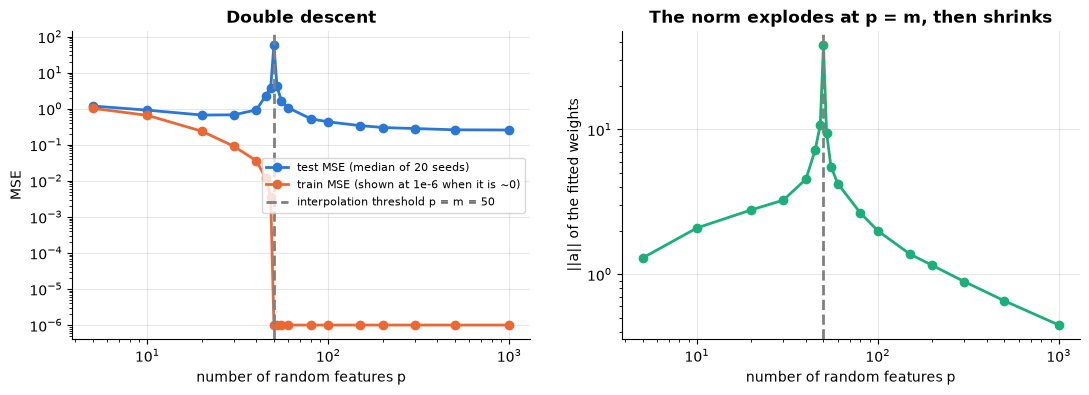

   p  test MSE  train MSE  ||a||
   5     1.182      1.019  1.295
  10     0.909      0.653  2.089
  20     0.665      0.237  2.786
  30     0.674      0.091  3.250
  40     0.923      0.036  4.538
  45     2.259      0.012  7.206
  48     3.857      0.004 10.761
  50    58.022      0.000 38.318
  52     4.123      0.000  9.525
  55     1.634      0.000  5.549
  60     1.054      0.000  4.228
  80     0.523      0.000  2.650
 100     0.430      0.000  1.992
 150     0.338      0.000  1.380
 200     0.300      0.000  1.150
 300     0.281      0.000  0.890
 500     0.259      0.000  0.655
1000     0.256      0.000  0.445


In [16]:
d_in, m_dd, n_test_dd = 10, 50, 1000
ps = [5, 10, 20, 30, 40, 45, 48, 50, 52, 55, 60, 80, 100, 150, 200, 300, 500, 1000]
test_err = np.zeros((20, len(ps))); train_err = np.zeros((20, len(ps))); norms = np.zeros((20, len(ps)))
for s in range(20):
    r = np.random.default_rng(100 + s)
    beta = r.normal(size=d_in)
    target = lambda X: 2 * np.tanh(X @ beta / np.sqrt(d_in))
    X_tr, X_te = r.normal(size=(m_dd, d_in)), r.normal(size=(n_test_dd, d_in))
    y_tr = target(X_tr) + 0.2 * r.normal(size=m_dd); y_te = target(X_te)
    W_rf = r.normal(size=(d_in, max(ps))) / np.sqrt(d_in)
    for j, p in enumerate(ps):
        F_tr, F_te = np.maximum(X_tr @ W_rf[:, :p], 0), np.maximum(X_te @ W_rf[:, :p], 0)
        a = np.linalg.lstsq(F_tr, y_tr, rcond=None)[0]          # min-norm solution when p > m
        test_err[s, j] = np.mean((F_te @ a - y_te) ** 2)
        train_err[s, j] = np.mean((F_tr @ a - y_tr) ** 2)
        norms[s, j] = np.linalg.norm(a)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(ps, np.median(test_err, 0), "o-", label="test MSE (median of 20 seeds)")
axes[0].loglog(ps, np.maximum(np.median(train_err, 0), 1e-6), "o-", label="train MSE (shown at 1e-6 when it is ~0)")
axes[0].axvline(m_dd, color="gray", ls="--", label="interpolation threshold p = m = 50")
axes[0].set_xlabel("number of random features p"); axes[0].set_ylabel("MSE"); axes[0].set_title("Double descent")
axes[0].legend(fontsize=8)
axes[1].loglog(ps, np.median(norms, 0), "o-", color=PALETTE[2])
axes[1].axvline(m_dd, color="gray", ls="--")
axes[1].set_xlabel("number of random features p"); axes[1].set_ylabel("||a|| of the fitted weights")
axes[1].set_title("The norm explodes at p = m, then shrinks"); plt.show()
dd = pd.DataFrame({"p": ps, "test MSE": np.median(test_err, 0), "train MSE": np.median(train_err, 0), "||a||": np.median(norms, 0)})
print(dd.round(3).to_string(index=False))

**What just happened?** The test error follows the classical U for $p < m$, **spikes at $p = m = 50$**, then falls again; at $p = 1000$ it is lower than at any $p < m$. The right panel explains the spike in the language of Section 6. At $p = m$ there is exactly one interpolating solution, and fitting the noise forces a huge weight norm (high Rademacher complexity). With $p \gg m$, many solutions interpolate, and the minimum-norm one is *smooth*: its norm, and hence its effective capacity, shrinks. **Parameter count is the wrong capacity measure; the norm (or margin) of the solution actually found is the right one.**

### 8.2 Memorising random labels (Zhang et al., 2017)

Zhang et al. showed that standard image networks can reach 100% training accuracy on CIFAR-10 even when the labels are replaced by **random** ones. So the hypothesis class is rich enough to shatter the training set, and its Rademacher complexity is essentially maximal. Yet with true labels the same networks generalise well. We reproduce this in miniature: an MLP with two hidden layers of 256 units on 500 handwritten digits (`sklearn.datasets.load_digits`, which ships with scikit-learn).

training time for both runs: 5.4 s
true labels  : train acc 1.000, test acc 0.954
random labels: train acc 1.000, test acc 0.128  (chance = 0.1)


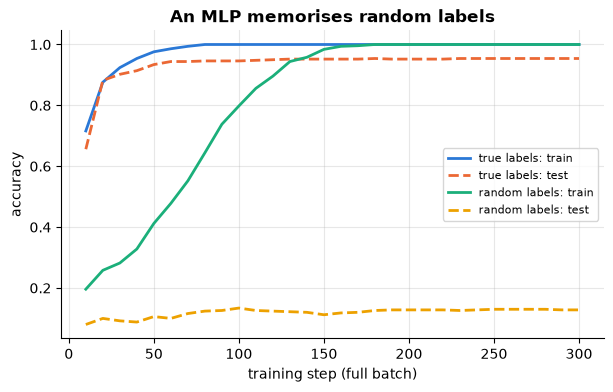

In [17]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd = torch.tensor(digits.data / 16.0, dtype=torch.float32)
yd = torch.tensor(digits.target)
perm = torch.randperm(len(yd), generator=torch.Generator().manual_seed(0))
tr_idx, te_idx = perm[:500], perm[500:1000]
y_random = torch.randint(0, 10, (500,), generator=torch.Generator().manual_seed(5))   # labels unrelated to images

def train_mlp(y_train, steps=300, seed=1):
    torch.manual_seed(seed)
    model = torch.nn.Sequential(torch.nn.Linear(64, 256), torch.nn.ReLU(),
                                torch.nn.Linear(256, 256), torch.nn.ReLU(), torch.nn.Linear(256, 10))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    curve = []
    for step in range(1, steps + 1):
        opt.zero_grad()
        loss = torch.nn.functional.cross_entropy(model(Xd[tr_idx]), y_train)
        loss.backward(); opt.step()
        if step % 10 == 0:
            with torch.no_grad():
                tr_acc = (model(Xd[tr_idx]).argmax(1) == y_train).float().mean().item()
                te_acc = (model(Xd[te_idx]).argmax(1) == yd[te_idx]).float().mean().item()
            curve.append((step, tr_acc, te_acc))
    return np.array(curve)

t0 = time.time()
curve_true = train_mlp(yd[tr_idx])
curve_rand = train_mlp(y_random)
print(f"training time for both runs: {time.time() - t0:.1f} s")
print(f"true labels  : train acc {curve_true[-1, 1]:.3f}, test acc {curve_true[-1, 2]:.3f}")
print(f"random labels: train acc {curve_rand[-1, 1]:.3f}, test acc {curve_rand[-1, 2]:.3f}  (chance = 0.1)")
plt.figure(figsize=(7, 4))
plt.plot(curve_true[:, 0], curve_true[:, 1], label="true labels: train")
plt.plot(curve_true[:, 0], curve_true[:, 2], "--", label="true labels: test")
plt.plot(curve_rand[:, 0], curve_rand[:, 1], label="random labels: train")
plt.plot(curve_rand[:, 0], curve_rand[:, 2], "--", label="random labels: test")
plt.xlabel("training step (full batch)"); plt.ylabel("accuracy"); plt.title("An MLP memorises random labels")
plt.legend(fontsize=8); plt.show()

**What just happened?** With random labels the network still reaches 100% training accuracy, a little later than with true labels: it simply **memorises** 500 arbitrary image-label pairs, and its test accuracy stays near chance. With true labels the *same* architecture, optimiser and number of steps reach high test accuracy. Any bound that depends only on the hypothesis class (VC dimension, worst-case Rademacher complexity) must therefore be **vacuous** for this network: the class can fit anything. Explaining generalisation in deep learning needs *algorithm- and data-dependent* quantities, such as the norm or margin of the solution SGD finds, flatness, compression, or PAC-Bayes bounds. This is active research.

### 8.3 No free lunch

**No-free-lunch theorem (Wolpert, 1996; Shalev-Shwartz & Ben-David, Thm 5.1):** averaged over *all* possible target functions, every learning algorithm has the same off-training-set accuracy, 50% for binary labels. A learner can only beat chance on unseen points by making **assumptions** (an inductive bias, i.e. a restricted $\mathcal H$ or a prior) that happen to match the world. We can verify this by brute force: there are $2^8 = 256$ Boolean functions on 3 bits.

In [18]:
inputs = np.array(list(itertools.product([0, 1], repeat=3)))      # the 8 possible inputs
train_ids, test_ids = [0, 1, 2, 4, 7], [3, 5, 6]                 # 5 seen inputs, 3 unseen inputs

def majority(train_x, train_y, x):                 # predict the majority training label
    return int(train_y.mean() >= 0.5)
def nearest_neighbour(train_x, train_y, x):        # 1-NN with Hamming distance
    return int(train_y[np.argmin(np.abs(train_x - x).sum(1))])
def anti_majority(train_x, train_y, x):            # deliberately silly learner
    return 1 - majority(train_x, train_y, x)

acc = {f.__name__: [] for f in (majority, nearest_neighbour, anti_majority)}
for labels in itertools.product([0, 1], repeat=8):               # every possible target function
    labels = np.array(labels)
    for f in (majority, nearest_neighbour, anti_majority):
        preds_ = [f(inputs[train_ids], labels[train_ids], inputs[i]) for i in test_ids]
        acc[f.__name__].append(np.mean(np.array(preds_) == labels[test_ids]))
for name, a in acc.items():
    print(f"{name:18s}: average off-training-set accuracy over all 256 targets = {np.mean(a):.4f}")

majority          : average off-training-set accuracy over all 256 targets = 0.5000
nearest_neighbour : average off-training-set accuracy over all 256 targets = 0.5000
anti_majority     : average off-training-set accuracy over all 256 targets = 0.5000


**What just happened?** All three learners, including the deliberately silly one, average **exactly 0.5000** on unseen inputs over all 256 possible worlds. Whatever pattern one learner exploits, there is an equally likely world where that pattern is reversed. In practice we never face "all possible targets": real data has structure (smoothness, locality, compositionality). Model design (CNNs for images, transformers for sequences) is the art of choosing inductive biases that match it.

## 9. Consequences for practice

The theory gives three practical tools: a guarantee for test sets, a way to plan sample sizes, and honest warnings about its own limits.

### 9.1 Why validation and test sets work

A model chosen **before** looking at the test set is a *single fixed hypothesis* from the test set's point of view, so Hoeffding applies directly. With probability $\ge 1 - \delta$:

$$|\hat R_{\text{test}}(h) - R(h)| \le \sqrt{\frac{\ln(2/\delta)}{2 n_{\text{test}}}}.$$

If you compare $K$ models on the same validation set and keep the best, apply the union bound and replace $\ln(2/\delta)$ by $\ln(2K/\delta)$. Peeking cost grows only **logarithmically** in $K$, but it is not zero. This is why a *final* test set must be touched once (see [`24_Research_Methods/03_statistical_significance_and_reporting`](../../24_Research_Methods/03_statistical_significance_and_reporting.ipynb)).

In [19]:
rows = []
for n_val in [100, 500, 1000, 5000, 10_000, 100_000]:
    rows.append({"n_test": n_val,
                 "±ε, 1 model (δ=0.05)": np.sqrt(np.log(2 / 0.05) / (2 * n_val)),
                 "±ε, best of 100 models": np.sqrt(np.log(2 * 100 / 0.05) / (2 * n_val)),
                 "±ε, best of 10,000 models": np.sqrt(np.log(2 * 10_000 / 0.05) / (2 * n_val))})
pd.DataFrame(rows).round(4)

,n_test,"±ε, 1 model (δ=0.05)","±ε, best of 100 models","±ε, best of 10,000 models"
0,100,0.1358,0.2036,0.2540
1,500,0.0607,0.0911,0.1136
2,1000,0.0429,0.0644,0.0803
3,5000,0.0192,0.0288,0.0359
4,10000,0.0136,0.0204,0.0254
5,100000,0.0043,0.0064,0.0080


**Reading the table:** with 1,000 test examples, a single model's accuracy is known to within about ±4.3 percentage points (95% confidence, distribution-free). Selecting the best of 100 models on the same set widens this to about ±6.4 points. Kaggle-style leaderboard overfitting is exactly the $\ln K$ term growing as thousands of submissions are compared on one public test set.

### 9.2 Sample-size planning

| Question | Formula | Example |
|---|---|---|
| test-set size for ±ε at confidence $1 - \delta$ | $n \ge \frac{\ln(2/\delta)}{2\varepsilon^2}$ | ε = 0.01, δ = 0.05 → 18,445 |
| training size, finite class, realisable | $m \ge \frac1\varepsilon(\ln\lvert\mathcal H\rvert + \ln\frac1\delta)$ | $\lvert\mathcal H\rvert = 2^{20}$, ε = δ = 0.01 → 1,847 |
| training size, VC class (rule of thumb) | $m \approx 10\, d_{VC}$ | linear model in 50-D: about 500 |
| detect a difference between two models | a paired test, e.g. McNemar ([`10_evaluation_metrics_comprehensive`](../10_evaluation_metrics_comprehensive.ipynb)) | depends on the disagreement rate |

### 9.3 Limits of the bounds

- **Worst-case:** they hold for *every* distribution, so they are loose for any particular one.
- **Class-based bounds ignore the optimiser:** SGD's implicit bias (towards small-norm, flat solutions) is invisible to VC theory. That is why deep networks with $10^8$ parameters generalise despite vacuous VC bounds.
- **i.i.d. assumption:** every bound here assumes training and test data come from the *same* distribution. Under distribution shift (new hospitals, new years, adversaries) none of them apply. Monitoring for drift ([`15_MLOps/06_monitoring`](../../15_MLOps/06_monitoring/01_monitoring.ipynb)) is the practical safeguard.
- **Useful anyway:** the *shapes* are right. Error falls like $1/\sqrt m$ (agnostic) or $1/m$ (realisable); capacity should grow slower than the data; norms and margins measure capacity better than parameter counts; and selecting among many models on one validation set costs $\ln K$.

## 10. Summary table

> 💬 **In plain English:** one table of every result in this notebook and what it means for daily ML work.

| Concept | Key statement | Depends on | Practical message |
|---|---|---|---|
| ERM | minimise the training error over $\mathcal H$ | $\mathcal H$, $m$ | the default learning rule; needs capacity control |
| Bias–variance | test MSE = noise + bias² + variance (squared loss) | the algorithm, $m$ | tune capacity to balance the two |
| PAC (finite $\mathcal H$) | $m \ge \frac1\varepsilon(\ln\lvert\mathcal H\rvert + \ln\frac1\delta)$ | $\ln\lvert\mathcal H\rvert$ | description length is capacity |
| Hoeffding | $\Pr[\lvert\bar Z - \mu\rvert \ge \varepsilon] \le 2e^{-2m\varepsilon^2}$ | $m$ | test-set error bars, distribution-free |
| VC dimension | learnable ⇔ $d_{VC} < \infty$; $m = \Theta(d/\varepsilon^2)$ agnostic | combinatorics of $\mathcal H$ | about 10 × $d_{VC}$ examples in practice |
| Rademacher | gap ≤ 2 × (fit to random signs) + $O(\sqrt{\ln(1/\delta)/m})$ | the data, norms | weight decay and margins control capacity |
| SRM | minimise error + penalty over nested classes | penalty choice | VC penalties are too conservative; data-dependent penalties and validation are sharper |
| Margin bound | capacity ≤ $R^2/\gamma^2 + 1$, independent of $d$ | margin, radius | why SVMs and kernels work in high dimensions |
| Double descent | test error can fall again past interpolation | the implicit bias of the solver | bigger can be better; parameter count is not capacity |
| No free lunch | averaged over all targets, every learner gets 50% | nothing | inductive bias is unavoidable |

## 11. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same theory explains scaling laws, benchmark overfitting and why regularisation works in deep learning.

- **Scaling laws and over-parameterised LLMs:** double descent and the failure of parameter-count capacity measures are why trillion-parameter models trained on trillions of tokens still generalise. Empirical scaling laws (Kaplan et al., 2020; Hoffmann et al., 2022, "Chinchilla") are the modern, data-driven successor to sample-complexity bounds ([`08_LLM/14_llm_architecture_innovations`](../../08_LLM/14_llm_architecture_innovations.ipynb)).
- **Benchmark overfitting and contamination:** the $\ln K$ penalty of Section 9 is why reusing public benchmarks (and leaking them into pre-training data) inflates reported LLM scores ([`08_LLM/08_evaluation`](../../08_LLM/08_evaluation/01_llm_evaluation.ipynb)).
- **Regularisation in deep learning:** weight decay, dropout, early stopping and data augmentation are all capacity-control tools; norm-based bounds (Section 6) and margin bounds (Section 7) motivate them ([`05_Deep_Learning/01_neural_network_fundamentals`](../../05_Deep_Learning/01_neural_network_fundamentals.ipynb)).
- **PAC-Bayes and compression bounds** give the first non-vacuous generalisation bounds for real neural networks, and connect to Bayesian deep learning ([`14_Mathematics/07_bayesian_ml`](../../14_Mathematics/07_bayesian_ml.ipynb)).
- **Conformal prediction** uses exchangeability and finite-sample arguments, cousins of Hoeffding, to give distribution-free prediction sets ([`14_conformal_prediction`](../14_conformal_prediction/01_conformal_prediction.ipynb)).
- **Kernels and the neural tangent kernel:** infinitely wide networks behave like kernel machines whose capacity is controlled by an RKHS norm, a direct link to the margin and Rademacher bounds here ([`02_kernel_methods`](02_kernel_methods.ipynb)).
- **Active learning** can beat the passive $1/\varepsilon$ rate by choosing which labels to request, sometimes exponentially for thresholds ([`13_active_learning`](../13_active_learning/01_active_learning.ipynb)).

## Recap (key takeaways)

- Learning = choosing $h$ from a class $\mathcal H$ using a finite i.i.d. sample. The goal is low **true risk**; we can only measure **empirical risk**.
- Excess risk = **estimation error** (shrinks with data) + **approximation error** (shrinks with a richer class). For squared loss: **test MSE = noise + bias² + variance**, verified by simulation.
- **PAC learning:** a finite class needs $O\big(\frac{\ln|\mathcal H| + \ln(1/\delta)}{\varepsilon}\big)$ examples when realisable, and $O\big(\frac{\ln|\mathcal H| + \ln(1/\delta)}{\varepsilon^2}\big)$ when agnostic.
- **Hoeffding** + **union bound** = uniform convergence for finite classes. For infinite classes the **growth function** replaces $|\mathcal H|$, and the **Sauer–Shelah lemma** makes it polynomial when $d_{VC} < \infty$.
- **VC dimension** exactly characterises binary PAC learnability. It is *not* the number of parameters.
- **Rademacher complexity** is data-dependent and scales with **weight norms**: the theoretical basis of weight decay and margins.
- **SRM** and **regularisation** trade training error against capacity; validation sets are justified by Hoeffding, and selecting among $K$ models costs $\ln K$.
- Modern over-parameterised models show **double descent** and can **memorise random labels**, so class-based bounds are vacuous for them. Norms, margins and the implicit bias of the optimiser are the right lens.
- **No free lunch:** without assumptions, no learner beats chance on unseen data.

## Practice problems

**1. (Easy)** A finite class has $|\mathcal H| = 2^{20}$ hypotheses and contains the target. How many examples guarantee error $\le 0.01$ with probability $\ge 0.99$?

<details><summary>Show solution</summary>

$m \ge \frac{1}{0.01}(20\ln 2 + \ln 100) = 100\,(13.863 + 4.605) = 1846.8$, so **1,847**.

```python
from math import log, ceil
eps, delta, H_size = 0.01, 0.01, 2 ** 20
m = ceil((log(H_size) + log(1 / delta)) / eps)
print("m >=", m)
```

</details>

**2. (Easy, conceptual)** What is the VC dimension of intervals on the real line? Give the set that is shattered and the labeling that cannot be realised on any 3 points.

<details><summary>Show solution</summary>

$d_{VC} = 2$. Any two distinct points are shattered: $(-,-)$ by an empty interval, $(+,-)$, $(-,+)$ and $(+,+)$ by suitable intervals. For any three points $x_1 < x_2 < x_3$, the labeling $(+, -, +)$ is impossible, because an interval containing $x_1$ and $x_3$ must contain $x_2$.

</details>

**3. (Medium, code)** "Signed thresholds" are $h(x) = \mathbb 1[x \ge t]$ **or** $h(x) = \mathbb 1[x < t]$. Show by brute force that they shatter 2 points but no set of 3 points.

<details><summary>Show solution</summary>

```python
import itertools
import numpy as np

def signed_threshold_ok(pts, lab):
    """h(x) = 1[x >= t] or h(x) = 1[x < t]: realisable iff the sorted labels are 0..01..1 or 1..10..0."""
    order = lab[np.argsort(pts)]
    up = all(order[i] <= order[i + 1] for i in range(len(order) - 1))
    down = all(order[i] >= order[i + 1] for i in range(len(order) - 1))
    return up or down

def shatters(points, ok):
    return all(ok(points, np.array(l)) for l in itertools.product([0, 1], repeat=len(points)))

print("2 points shattered:", shatters(np.array([0.1, 0.6]), signed_threshold_ok))
rng_ = np.random.default_rng(0)
print("any random 3-point set shattered:", any(shatters(rng_.random(3), signed_threshold_ok) for _ in range(200)))
```
For three points $x_1 < x_2 < x_3$, the labelings $(+, -, +)$ and $(-, +, -)$ are not monotone, so they cannot be realised. Hence $d_{VC} = 2$.

</details>

**4. (Medium, code)** How large must a test set be so that the measured accuracy is within ±1 percentage point of the true accuracy with 95% confidence (distribution-free)? Verify by simulation.

<details><summary>Show solution</summary>

By Hoeffding: $n \ge \ln(2/0.05)/(2 \cdot 0.01^2) = 18{,}444.4$, so **18,445**. If you know the accuracy is near 0.9, the binomial variance $0.9 \times 0.1$ gives a much smaller CLT-based answer (about 3,458), which is why the simulated failure rate is far below 5%.

```python
import numpy as np
from math import log, ceil
eps, delta = 0.01, 0.05
n = ceil(log(2 / delta) / (2 * eps ** 2))
print("test-set size needed:", n)
# simulate: a model with true accuracy 0.9, evaluated on n test points, 20,000 times
r = np.random.default_rng(0)
est = r.binomial(n, 0.9, size=20000) / n
print("fraction of test sets with |estimate - 0.9| > 0.01:", np.mean(np.abs(est - 0.9) > eps))
```

</details>

**5. (Medium, code)** For $k$-nearest-neighbour regression with fixed training inputs and noise variance $\sigma^2$, show that the variance of the prediction at a point is $\sigma^2/k$, and that the bias grows with $k$.

<details><summary>Show solution</summary>

The prediction is the mean of $k$ noisy labels, $\frac1k\sum_{j}(f(x_{(j)}) + \varepsilon_j)$, whose variance is $\sigma^2/k$. The bias is $f(x_0) - \frac1k\sum_j f(x_{(j)})$, which grows as the neighbours move further from $x_0$ where $f$ is curved. Here $x_0 = 0.5$ and $f(x) = \sin(2\pi x)$.

```python
import numpy as np
# k-NN regression at a fixed test point x0 = 0.5, with training inputs on a fixed fine grid
# so that the k nearest neighbours are always the same points; only the noise is random.
sigma, reps = 0.5, 20000
x_grid = np.linspace(0, 1, 201)
f = lambda x: np.sin(2 * np.pi * x)
r = np.random.default_rng(0)
for k in [1, 5, 25]:
    nn = np.argsort(np.abs(x_grid - 0.5))[:k]                 # indices of the k nearest neighbours
    preds = (f(x_grid[nn])[None, :] + sigma * r.normal(size=(reps, k))).mean(axis=1)
    print(f"k = {k:2d}: variance = {preds.var():.4f}  (theory sigma^2/k = {sigma**2 / k:.4f}), "
          f"bias^2 = {(preds.mean() - f(0.5))**2:.5f}")
```

</details>

**6. (Hard, code)** Compute the empirical Rademacher complexity of intervals (as $\pm 1$ classifiers) on $m$ points by enumerating all their behaviours, and compare with Massart's bound $\sqrt{2\ln N / m}$, where $N$ is the number of behaviours.

<details><summary>Show solution</summary>

```python
import numpy as np
from math import comb, log, sqrt

def rademacher_intervals(m, n_sigma=4000, seed=0):
    """Exact sup over all interval labelings (mapped to +-1) for each sigma, averaged over sigma."""
    r = np.random.default_rng(seed)
    beh = [-np.ones(m)]                                        # the empty interval
    for i in range(m):
        for j in range(i, m):
            h = -np.ones(m); h[i:j + 1] = 1; beh.append(h)
    B = np.array(beh)                                         # C(m+1, 2) + 1 behaviours
    sig = r.choice([-1.0, 1.0], size=(n_sigma, m))
    return (sig @ B.T / m).max(axis=1).mean(), len(B)

for m in [10, 40, 160]:
    rad, n_beh = rademacher_intervals(m)
    print(f"m = {m:3d}: behaviours = {n_beh}, Rademacher = {rad:.4f}, Massart bound = {sqrt(2 * log(n_beh) / m):.4f}")
```

</details>

**7. (Hard, conceptual)** A colleague says: "My network has $10^7$ parameters and only $10^5$ training images, so by VC theory it must overfit." Using Sections 6–8, explain what is right and wrong about this argument.

<details><summary>Show solution</summary>

*Right:* the class of all functions this architecture can represent has VC dimension far above $10^5$. Zhang et al. (and Section 8.2) show such networks can fit random labels, so **class-based** bounds (VC, worst-case Rademacher) are vacuous and *guarantee* nothing.

*Wrong:* "no guarantee" is not "must overfit". Generalisation depends on *which* function training finds. SGD from small initialisation has an implicit bias towards low-norm / large-margin / flat solutions, and data augmentation and weight decay restrict it further. Norm-, margin- and PAC-Bayes-based bounds can be much smaller than parameter counts, and double descent (Section 8.1) shows test error can *fall* as parameters grow past the interpolation threshold. The right check is a held-out test set, which Hoeffding justifies.

</details>

## Further reading (additional learning resources)

- S. Shalev-Shwartz and S. Ben-David, *Understanding Machine Learning: From Theory to Algorithms*, Cambridge University Press, 2014. Chapters 2–6 (PAC, uniform convergence, VC, the fundamental theorem), 7 (SRM), 26 (Rademacher). Free PDF on the authors' website.
- M. Mohri, A. Rostamizadeh and A. Talwalkar, *Foundations of Machine Learning*, 2nd ed., MIT Press, 2018. Chapters 2–3. Free online.
- Y. Abu-Mostafa, M. Magdon-Ismail and H.-T. Lin, *Learning From Data*, 2012. A gentle treatment of the VC bound; the companion Caltech CS156 lectures are free online.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., chapter 7 (bias–variance, effective degrees of freedom, model assessment).
- M. Belkin, D. Hsu, S. Ma and S. Mandal, "Reconciling modern machine-learning practice and the classical bias–variance trade-off", *PNAS*, 2019 (double descent).
- C. Zhang, S. Bengio, M. Hardt, B. Recht and O. Vinyals, "Understanding deep learning requires rethinking generalization", ICLR 2017.

## Next notebook

Continue with [`02_kernel_methods.ipynb`](02_kernel_methods.ipynb). It puts the margin and norm-based capacity ideas to work: feature maps, the representer theorem, kernel ridge regression, scalable approximations and the kernel two-sample test.